<a href="https://colab.research.google.com/github/RZchive/ProbStat_Penggunaan_Platform_Artificial_Intelligence_Dan_Penggunaan_Gadget/blob/main/Analisis_Validitas_Reliabilitas_Dua_Topik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Statistika Dua Topik Penelitian: Validitas, Reliabilitas, dan Statistika Deskriptif
**Alat:** Google Colab (Python) · **Acuan:** Modul Praktikum *Pengujian Validitas dan Reliabilitas Instrumen*

Notebook ini dijalankan **berurutan dari sel paling atas**. Seluruh angka dihitung langsung dari file Excel respons Google Forms; tidak ada nilai yang diketik manual kecuali kamus skala Likert, daftar koreksi penulisan, dan keputusan metodologis yang dijelaskan pada sel terkait.

**Topik 1** – Penggunaan platform AI di kalangan mahasiswa dan dampaknya terhadap aspek psikologis (2 dimensi, 7 + 7 butir).
**Topik 2** – Kebiasaan penggunaan teknologi digital dan prokrastinasi akademik terhadap stres akademik (3 dimensi, 6 + 4 + 5 butir).

### Perubahan terhadap kode modul (dan alasannya)
| No | Bagian modul | Perubahan | Alasan |
|---|---|---|---|
| 1 | Langkah 3 | Kolom demografi **tidak** diambil dengan `iloc[:, 5:]`. Butir dikenali dari pola judul `Dimensi [pernyataan]`. | Pada file ini kolom 1–6 berisi Timestamp, Score, Kelas, Jenis Kelamin, jumlah platform, dan jumlah platform premium; kolom ke-21 (durasi gadget) terletak **di antara** butir Topik 1 dan Topik 2. Asumsi 5 kolom pertama akan menyertakan kolom non-butir dan memutus regex. |
| 2 | Langkah 3 | Ditambah pemeriksaan data duplikat, nilai konstan, *straight-lining*, dan penormalan judul kolom. | Diminta pada instruksi bagian B. |
| 3 | Langkah 4 | `replace(...)` diganti `map(...)` setelah label dinormalkan (spasi/huruf). | Label tak dikenal otomatis menjadi `NaN` sehingga terdeteksi, bukan lolos diam-diam. |
| 4 | Langkah 5 | Pengelompokan dimensi memakai kamus nama dimensi → topik, bukan hanya regex. | Agar dua topik terpisah dan salah ketik pada judul kolom tidak membuat dimensi terpecah. |
| 5 | Langkah 6–7 | Logika r hitung, r tabel, corrected r, Cronbach's α, dan α jika butir dihapus **sama** dengan modul. Ditambah kolom p-value, kriteria corrected r ≥ 0,30, dan rekomendasi sesuai tabel Pedoman Pengambilan Keputusan modul. | Diminta pada instruksi bagian C–D. |
| 6 | Tambahan | Pemeriksaan *reverse coding*, analisis sensitivitas, statistika deskriptif, grafik. | Diminta pada instruksi bagian B, E, dan G. |
| 7 | Langkah 8 | Berkas Excel berisi lebih banyak lembar (per topik). | Agar kedua topik terpisah. |

## Langkah 1. Persiapan lingkungan

In [1]:
import re, os, json, textwrap, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
try:
    from google.colab import files      # tersedia hanya di Google Colab
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

OUT = "hasil"
os.makedirs(f"{OUT}/grafik", exist_ok=True)
print("Berjalan di Google Colab:", DI_COLAB)

Berjalan di Google Colab: True


## Langkah 2. Unggah berkas data
Di Colab klik **Choose Files** dan pilih berkas `.xlsx` hasil ekspor Google Forms.

In [2]:
if DI_COLAB:
    up = files.upload()
    nama_file = list(up.keys())[0]
else:                                    # menjalankan di luar Colab: isi nama/jalur berkas
    nama_file = os.environ.get("DATA_XLSX", "Blank_Quiz_Responses.xlsx")
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


## Langkah 3. Membaca data dan pemeriksaan kondisi awal

In [3]:
df_mentah = pd.read_excel(nama_file)
print("Jumlah responden (baris):", len(df_mentah))
print("Jumlah kolom            :", df_mentah.shape[1])
print("Total sel kosong        :", int(df_mentah.isna().sum().sum()))
print("Baris duplikat (seluruh kolom)      :", int(df_mentah.duplicated().sum()))
print("Rentang waktu pengisian :", df_mentah["Timestamp"].min(), "s.d.", df_mentah["Timestamp"].max())

# Daftar kolom beserta tipe dan jumlah data kosong
ringkas_kolom = pd.DataFrame({
    "No": range(1, df_mentah.shape[1] + 1),
    "Judul kolom (mentah)": [repr(c) for c in df_mentah.columns],
    "Tipe": df_mentah.dtypes.astype(str).values,
    "Kosong": df_mentah.isna().sum().values,
    "Nilai unik": df_mentah.nunique().values,
})
ringkas_kolom

Jumlah responden (baris): 38
Jumlah kolom            : 36
Total sel kosong        : 0
Baris duplikat (seluruh kolom)      : 0
Rentang waktu pengisian : 2026-11-09 13:00:28.960000 s.d. 2026-11-09 19:01:40.300000


,No,Judul kolom (mentah),Tipe,Kosong,Nilai unik
0,1,'Timestamp',datetime64[ns],0,38
1,2,'Score',int64,0,1
2,3,'Kelas',object,0,1
3,4,'Jenis Kelamin',object,0,2
4,5,'Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek',object,0,14
5,6,'Jumlah Platform AI yang berlangganan secara premium (bukan free)',object,0,9
6,7,'Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir seti...,object,0,5
7,8,'Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi...,object,0,5
8,9,'Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide at...,object,0,4
9,10,'Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjaka...,object,0,4


**Temuan awal yang perlu diperhatikan:** kolom `Score` dan `Kelas` hanya memiliki 1 nilai unik (konstan), sehingga tidak informatif untuk analisis. Kolom jumlah platform AI bertipe campuran (angka dan teks bebas), dan judul kolom memuat kesalahan penulisan serta spasi berlebih. Semua itu ditangani pada langkah berikut.

## Langkah 4. Normalisasi judul kolom (makna pernyataan tidak diubah)
Koreksi hanya mencakup salah ketik jelas dan spasi/tanda baca yang berlebih.

In [4]:
KOREKSI_TEKS = {
    "[aya merasa": "[Saya merasa",         # huruf 'S' hilang (2 butir)
    "[aya sering": "[Saya sering",         # huruf 'S' hilang (1 butir)
    "Rsspon emosional": "Respons emosional",
    "./projek": "/projek",
    "membatu": "membantu",
}

def norm_kolom(c):
    c = re.sub(r"\s+", " ", str(c)).strip()          # spasi ganda / spasi di awal
    for salah, benar in KOREKSI_TEKS.items():
        c = c.replace(salah, benar)
    c = re.sub(r"\.\s+\[", " [", c)                  # 'Prokrastinasi akademik. [' -> tanpa titik
    c = re.sub(r"\s+\[", " [", c)
    return c

POLA_BUTIR = re.compile(r"^(.*?) \[(.*)\]\s*$")
kol_butir = [c for c in df_mentah.columns if POLA_BUTIR.match(norm_kolom(c))]
kol_lain = [c for c in df_mentah.columns if c not in kol_butir]
print("Kolom butir :", len(kol_butir))
print("Kolom lain  :", [norm_kolom(c) for c in kol_lain])

perubahan = pd.DataFrame({"Sebelum": [str(c) for c in df_mentah.columns],
                          "Sesudah": [norm_kolom(c) for c in df_mentah.columns]})
perubahan = perubahan[perubahan.Sebelum != perubahan.Sesudah].reset_index(drop=True)
print(f"\nJudul kolom yang dinormalkan: {len(perubahan)} dari {df_mentah.shape[1]}")
perubahan

Kolom butir : 29
Kolom lain  : ['Timestamp', 'Score', 'Kelas', 'Jenis Kelamin', 'Jumlah Platform AI yang rutin digunakan untuk membantu menyelesaikan tugas atau projek', 'Jumlah Platform AI yang berlangganan secara premium (bukan free)', 'Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan']

Judul kolom yang dinormalkan: 19 dari 36


,Sebelum,Sesudah
0,Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek,Jumlah Platform AI yang rutin digunakan untuk membantu menyelesaikan tugas atau projek
1,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide ata...,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide ata...
2,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan men...,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan me...
3,"Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai deng...","Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai deng..."
4,Kebiasaan penggunaan teknologi digital [Saya sering mengerjakan tugas kuliah sambil m...,Kebiasaan penggunaan teknologi digital [Saya sering mengerjakan tugas kuliah sambil me...
5,Kebiasaan penggunaan teknologi digital [Saya sering memeriksa notifikasi smartphone m...,Kebiasaan penggunaan teknologi digital [Saya sering memeriksa notifikasi smartphone me...
6,Kebiasaan penggunaan teknologi digital [aya sering menunda pengerjaan tugas karena le...,Kebiasaan penggunaan teknologi digital [Saya sering menunda pengerjaan tugas karena le...
7,Kebiasaan penggunaan teknologi digital [Saya merasa menggunakan AI tidak membutuhkan ...,Kebiasaan penggunaan teknologi digital [Saya merasa menggunakan AI tidak membutuhkan t...
8,Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberik...,Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberika...
9,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI k...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI ka...


## Langkah 5. Memisahkan topik dan mengelompokkan butir per dimensi
Pengelompokan memakai **nama dimensi pada judul kolom**, bukan posisi kolom.

In [5]:
PETA_DIMENSI = {   # nama dimensi (setelah normalisasi) -> (topik, nama ringkas, kode)
    "Penggunaan AI pada tugas atau projek kuliah": ("Topik 1", "Penggunaan AI pada tugas/projek", "T1D1"),
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": ("Topik 1", "Aspek psikologis penggunaan AI", "T1D2"),
    "Kebiasaan penggunaan teknologi digital": ("Topik 2", "Kebiasaan penggunaan teknologi digital", "T2D1"),
    "Prokrastinasi akademik": ("Topik 2", "Prokrastinasi akademik", "T2D2"),
    "Respons emosional": ("Topik 2", "Respons emosional", "T2D3"),
}

DIM = {}          # kode dimensi -> {topik, nama, butir:[kode butir]}
kamus_rows = []   # kamus butir
nama_ke_kode = {} # judul kolom mentah -> kode butir
for kol in kol_butir:
    dim_asli, pernyataan = POLA_BUTIR.match(norm_kolom(kol)).groups()
    topik, nama, kd = PETA_DIMENSI[dim_asli]      # KeyError bila ada dimensi tak dikenal
    d = DIM.setdefault(kd, {"topik": topik, "nama": nama, "butir": []})
    kode = f"{kd}_B{len(d['butir']) + 1}"
    d["butir"].append(kode); nama_ke_kode[kol] = kode
    kamus_rows.append({"Kode": kode, "Topik": topik, "Dimensi": nama,
                       "Butir": f"B{len(d['butir'])}", "Pernyataan": pernyataan})
kamus = pd.DataFrame(kamus_rows)

for kd, d in DIM.items():
    print(f"{d['topik']} | {d['nama']}: {len(d['butir'])} butir")
print("\nTotal butir:", len(kamus))
kamus

Topik 1 | Penggunaan AI pada tugas/projek: 7 butir
Topik 1 | Aspek psikologis penggunaan AI: 7 butir
Topik 2 | Kebiasaan penggunaan teknologi digital: 6 butir
Topik 2 | Prokrastinasi akademik: 4 butir
Topik 2 | Respons emosional: 5 butir

Total butir: 29


,Kode,Topik,Dimensi,Butir,Pernyataan
0,T1D1_B1,Topik 1,Penggunaan AI pada tugas/projek,B1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.
1,T1D1_B2,Topik 1,Penggunaan AI pada tugas/projek,B2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.
2,T1D1_B3,Topik 1,Penggunaan AI pada tugas/projek,B3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas/projek
3,T1D1_B4,Topik 1,Penggunaan AI pada tugas/projek,B4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.
4,T1D1_B5,Topik 1,Penggunaan AI pada tugas/projek,B5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.
5,T1D1_B6,Topik 1,Penggunaan AI pada tugas/projek,B6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.
6,T1D1_B7,Topik 1,Penggunaan AI pada tugas/projek,B7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.
7,T1D2_B1,Topik 1,Aspek psikologis penggunaan AI,B1,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.
8,T1D2_B2,Topik 1,Aspek psikologis penggunaan AI,B2,Saya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.
9,T1D2_B3,Topik 1,Aspek psikologis penggunaan AI,B3,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternati...


## Langkah 6. Mengubah jawaban Likert menjadi angka

In [6]:
skala = {"sangat tidak setuju (sts)": 1, "tidak setuju (ts)": 2, "netral (n)": 3,
         "setuju (s)": 4, "sangat setuju (ss)": 5}

label_bersih = df_mentah[kol_butir].rename(columns=nama_ke_kode).apply(
    lambda s: s.astype(str).str.replace(r"\s+", " ", regex=True).str.strip().str.lower())
num = label_bersih.apply(lambda s: s.map(skala))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca / di luar skala.
print("Sel yang gagal dikonversi :", int(num.isna().sum().sum()))
print("Nilai di luar 1-5         :", int(((num < 1) | (num > 5)).sum().sum()))
print("Label jawaban unik (mentah):")
print(df_mentah[kol_butir].stack().value_counts().to_string())
num = num.astype(int)

Sel yang gagal dikonversi : 0
Nilai di luar 1-5         : 0
Label jawaban unik (mentah):
Netral (N)                   403
Setuju (S)                   316
Tidak Setuju (TS)            182
Sangat Setuju (SS)           144
Sangat Tidak Setuju (STS)     57


## Langkah 7. Membersihkan variabel pendukung (Topik 1) dan memeriksa kualitas respons

In [7]:
def cari(kata):
    return [c for c in kol_lain if kata.lower() in str(c).lower()][0]

pend = pd.DataFrame({
    "Kelas": df_mentah[cari("Kelas")].astype(str).str.strip(),
    "Jenis_Kelamin": df_mentah[cari("Jenis Kelamin")].astype(str).str.strip(),
    "Platform_AI_mentah": df_mentah[cari("rutin digunakan")],
    "Premium_mentah": df_mentah[cari("premium")],
    "Durasi_Gadget": df_mentah[cari("Durasi")].astype(str).str.strip(),
})

# Entri teks bebas dikonversi secara eksplisit dan terdokumentasi (bukan ditebak otomatis).
# Rentang ("2-5", "3 atau 4", ...) diwakili titik tengahnya dan ditandai 'ambigu'.
MAP_PLATFORM = {
    "3 atau 4 Platforn AI": 3.5, "Tiga": 3, "5-7(tergantung tugas)": 6, "3, gpt gemini claude": 3,
    "1-3 AI": 2, "claude": 1, "ChatGpt, Gemini, Antigravity, Claude": 4, "2-5": 3.5,
    "Claude AI, Dreamina AI, Hyper AI, Antigravity AI": 4,
}
MAP_PREMIUM = {"Satu (Gemini)": 1, "chatgpt": 1, "1, gemini": 1, "Gemini pro": 1, "Google Ai pro": 1}
AMBIGU = {"3 atau 4 Platforn AI", "5-7(tergantung tugas)", "1-3 AI", "2-5"}

def ke_angka(v, peta):
    if isinstance(v, (int, float, np.integer, np.floating)): return float(v)
    return float(peta[str(v)])           # KeyError bila ada entri baru yang belum dipetakan

pend["N_Platform_AI"] = pend["Platform_AI_mentah"].apply(lambda v: ke_angka(v, MAP_PLATFORM))
pend["N_Platform_Premium"] = pend["Premium_mentah"].apply(lambda v: ke_angka(v, MAP_PREMIUM))
pend["Platform_ambigu"] = pend["Platform_AI_mentah"].astype(str).isin(AMBIGU)
MAP_DURASI = {"< 4 jam": 1, "4 - 7 jam": 2, "7 - 10 jam": 3, "> 10 jam": 4}
pend["Durasi_Gadget_ordinal"] = pend["Durasi_Gadget"].map(MAP_DURASI)
assert pend["Durasi_Gadget_ordinal"].notna().all()

log_pend = pd.concat([
    pend.loc[pend["Platform_AI_mentah"].apply(lambda v: isinstance(v, str)), ["Platform_AI_mentah", "N_Platform_AI"]]
        .rename(columns={"Platform_AI_mentah": "Entri asli", "N_Platform_AI": "Nilai dipakai"}).assign(Variabel="Jumlah platform AI rutin"),
    pend.loc[pend["Premium_mentah"].apply(lambda v: isinstance(v, str)), ["Premium_mentah", "N_Platform_Premium"]]
        .rename(columns={"Premium_mentah": "Entri asli", "N_Platform_Premium": "Nilai dipakai"}).assign(Variabel="Jumlah platform premium"),
])[["Variabel", "Entri asli", "Nilai dipakai"]].reset_index(drop=True)
print("Entri teks bebas yang dikonversi:", len(log_pend), "| di antaranya rentang ambigu:", int(pend.Platform_ambigu.sum()))
print("Responden dengan platform premium > platform rutin (inkonsisten):",
      int((pend.N_Platform_Premium > pend.N_Platform_AI).sum()))
display(log_pend)

# --- Kualitas respons: straight-lining dan duplikat pada butir ---
sd_resp = num.std(axis=1, ddof=1)
print("\nResponden menjawab SELURUH 29 butir dengan nilai sama (straight-lining):", int((sd_resp == 0).sum()))
print("Duplikat berdasarkan 29 butir saja:", int(num.duplicated().sum()))
print("Butir tanpa variasi (varians = 0):", [c for c in num.columns if num[c].var() == 0])
print("SD minimum antarbutir per responden:", round(sd_resp.min(), 3))

Entri teks bebas yang dikonversi: 14 | di antaranya rentang ambigu: 4
Responden dengan platform premium > platform rutin (inkonsisten): 0


,Variabel,Entri asli,Nilai dipakai
0,Jumlah platform AI rutin,3 atau 4 Platforn AI,3.5
1,Jumlah platform AI rutin,Tiga,3.0
2,Jumlah platform AI rutin,5-7(tergantung tugas),6.0
3,Jumlah platform AI rutin,"3, gpt gemini claude",3.0
4,Jumlah platform AI rutin,1-3 AI,2.0
5,Jumlah platform AI rutin,claude,1.0
6,Jumlah platform AI rutin,"ChatGpt, Gemini, Antigravity, Claude",4.0
7,Jumlah platform AI rutin,2-5,3.5
8,Jumlah platform AI rutin,"Claude AI, Dreamina AI, Hyper AI, Antigravity AI",4.0
9,Jumlah platform premium,Satu (Gemini),1.0



Responden menjawab SELURUH 29 butir dengan nilai sama (straight-lining): 0
Duplikat berdasarkan 29 butir saja: 0
Butir tanpa variasi (varians = 0): []
SD minimum antarbutir per responden: 0.455


## Kondisi data sebelum dan sesudah pembersihan

In [8]:
tabel_pembersihan = pd.DataFrame([
    ["Jumlah responden (baris)", len(df_mentah), len(num)],
    ["Jumlah kolom", df_mentah.shape[1], num.shape[1] + 5],
    ["Kolom butir Likert", len(kol_butir), num.shape[1]],
    ["Sel kosong pada butir", int(df_mentah[kol_butir].isna().sum().sum()), int(num.isna().sum().sum())],
    ["Baris duplikat", int(df_mentah.duplicated().sum()), int(num.duplicated().sum())],
    ["Judul kolom bermasalah (salah ketik/spasi/titik)", len(perubahan), 0],
    ["Jawaban Likert berupa teks", int(df_mentah[kol_butir].size), 0],
    ["Jawaban Likert gagal dikonversi / di luar skala", "-", 0],
    ["Entri non-numerik pada jumlah platform (AI & premium)", len(log_pend), 0],
    ["Kolom konstan (Score, Kelas)", 2, "2 (dikeluarkan dari analisis)"],
], columns=["Aspek pemeriksaan", "Sebelum", "Sesudah"])
tabel_pembersihan

,Aspek pemeriksaan,Sebelum,Sesudah
0,Jumlah responden (baris),38,38
1,Jumlah kolom,36,34
2,Kolom butir Likert,29,29
3,Sel kosong pada butir,0,0
4,Baris duplikat,0,0
5,Judul kolom bermasalah (salah ketik/spasi/titik),19,0
6,Jawaban Likert berupa teks,1102,0
7,Jawaban Likert gagal dikonversi / di luar skala,-,0
8,Entri non-numerik pada jumlah platform (AI & premium),14,0
9,"Kolom konstan (Score, Kelas)",2,2 (dikeluarkan dari analisis)


Tidak ada responden maupun butir yang dihapus pada tahap pembersihan: tidak ada data kosong, duplikat, label di luar skala, atau butir tanpa variasi.

## Langkah 8. Fungsi uji validitas dan reliabilitas (mengikuti modul)

In [9]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05 dua sisi; df={n-2}) = {r_tabel:.3f}")

def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

def rekomendasi(valid, a_hapus, a_dim):
    """Mengikuti tabel 'Pedoman Pengambilan Keputusan' pada modul (butir tidak otomatis dibuang)."""
    if np.isnan(a_hapus): return "Pertahankan" if valid else "Tinjau ulang (dimensi ≤ 2 butir)"
    naik = a_hapus > a_dim
    if valid and not naik: return "Pertahankan"
    if valid and naik: return "Tinjau isi butir (kemungkinan beda konstruk)"
    if (not valid) and naik: return "Revisi redaksi / pertimbangkan dibuang, lalu uji ulang"
    return "Tinjau ulang sebelum dibuang (pertimbangkan validitas isi)"

def uji_dimensi(x, topik, nama):
    """x: DataFrame skor butir SATU dimensi saja (tidak pernah digabung antardimensi)."""
    total = x.sum(axis=1); k = x.shape[1]; a = cronbach_alpha(x)
    val, alp = [], []
    for kode in x.columns:
        r, p = stats.pearsonr(x[kode], total)                 # r hitung (butir vs total dimensi)
        rc, _ = stats.pearsonr(x[kode], total - x[kode])      # corrected item-total
        ah = cronbach_alpha(x.drop(columns=kode)) if k > 2 else np.nan
        valid = r > r_tabel
        val.append({"Topik": topik, "Dimensi": nama, "Butir": kode.split("_")[1], "Kode": kode,
                    "r hitung": r, "r tabel": r_tabel, "Corrected r": rc, "p-value": p,
                    "Keterangan": "Valid" if valid else "Tidak valid",
                    "Corrected r ≥ 0,30": "Ya" if rc >= 0.30 else "Tidak",
                    "Alpha jika dihapus": ah, "Rekomendasi": rekomendasi(valid, ah, a)})
    rel = {"Topik": topik, "Dimensi": nama, "Jumlah butir": k, "Cronbach's alpha": a,
           "Kategori": kategori(a), "Rata-rata korelasi antarbutir":
           (x.corr().values[np.triu_indices(k, 1)]).mean()}
    return val, rel

n = 38 | r tabel (α=0,05 dua sisi; df=36) = 0.320


## Langkah 9. Pemeriksaan arah butir dan *reverse coding*

**Prinsip keputusan.** Butir dibalik (6 − skor) hanya bila (a) secara konseptual berlawanan arah dengan konstruk yang diukur **dan** (b) data mendukung, yaitu korelasi butir-total terkoreksi bernilai negatif. Jika konsep dan data tidak sejalan, butir ditinjau, bukan dibalik secara mekanis.

Butir kandidat berarah positif / berlawanan makna diperiksa berikut.

In [10]:
KANDIDAT_BALIK = {
    "T1D1_B7": "Memeriksa kembali kebenaran informasi AI (verifikasi)",
    "T1D2_B6": "AI membuat lebih tertarik mempelajari materi (dampak positif)",
    "T1D2_B7": "Tetap yakin pada kemampuan diri meski memakai AI (dampak positif)",
    "T2D3_B4": "Merasa lega setelah mengumpulkan tugas (afek positif)",
}
def dim_dari(kode): return kode.split("_")[0]

cek = []
for kode, ket in KANDIDAT_BALIK.items():
    kd = dim_dari(kode); x = num[DIM[kd]["butir"]]
    xr = x.copy(); xr[kode] = 6 - xr[kode]
    rc = stats.pearsonr(x[kode], x.sum(axis=1) - x[kode])[0]
    rc_r = stats.pearsonr(xr[kode], xr.sum(axis=1) - xr[kode])[0]
    cek.append({"Butir": kode, "Makna butir": ket, "Corrected r (skor asli)": rc,
                "Corrected r (jika dibalik)": rc_r, "α dimensi (asli)": cronbach_alpha(x),
                "α dimensi (dibalik)": cronbach_alpha(xr),
                "Keputusan": "Tidak dibalik" if rc > 0 else "Dibalik"})
cek_reverse = pd.DataFrame(cek)
print("Jumlah butir (seluruh instrumen) dengan corrected r negatif pada skor asli:",
      int(sum(stats.pearsonr(num[c], num[DIM[dim_dari(c)]["butir"]].sum(axis=1) - num[c])[0] < 0 for c in num.columns)))
cek_reverse.round(3)

Jumlah butir (seluruh instrumen) dengan corrected r negatif pada skor asli: 0


,Butir,Makna butir,Corrected r (skor asli),Corrected r (jika dibalik),α dimensi (asli),α dimensi (dibalik),Keputusan
0,T1D1_B7,Memeriksa kembali kebenaran informasi AI (verifikasi),0.644,-0.644,0.865,0.613,Tidak dibalik
1,T1D2_B6,AI membuat lebih tertarik mempelajari materi (dampak positif),0.713,-0.713,0.904,0.680,Tidak dibalik
2,T1D2_B7,Tetap yakin pada kemampuan diri meski memakai AI (dampak positif),0.671,-0.671,0.904,0.716,Tidak dibalik
3,T2D3_B4,Merasa lega setelah mengumpulkan tugas (afek positif),0.643,-0.643,0.873,0.516,Tidak dibalik


**Keputusan:** tidak ada butir yang dibalik. Seluruh butir, termasuk yang bermakna positif, berkorelasi **positif** dengan butir lain dalam dimensinya; membaliknya akan menurunkan α secara drastis. Untuk butir "merasa lega" (T2D3_B4), alasan konseptual dan implikasinya terhadap indikator stres dijelaskan pada sel sensitivitas di bawah.

## Langkah 10. Uji validitas (Pearson Product Moment) dan reliabilitas (Cronbach's α)

In [11]:
hasil_val, hasil_rel = [], []
for kd, d in DIM.items():
    v, r_ = uji_dimensi(num[d["butir"]], d["topik"], d["nama"])
    hasil_val += v; hasil_rel.append(r_)
tabel_validitas = pd.DataFrame(hasil_val)
tabel_reliabilitas = pd.DataFrame(hasil_rel)

def tampil(df, kolom=None):
    return df.round({"r hitung": 3, "r tabel": 3, "Corrected r": 3, "p-value": 4, "Alpha jika dihapus": 3,
                     "Cronbach's alpha": 3, "Rata-rata korelasi antarbutir": 3})

for topik in ["Topik 1", "Topik 2"]:
    print("=" * 30, topik, "=" * 30)
    display(tampil(tabel_validitas[tabel_validitas.Topik == topik]
                   .drop(columns=["Topik", "Kode"])))
    display(tampil(tabel_reliabilitas[tabel_reliabilitas.Topik == topik].drop(columns="Topik")))

============================== Topik 1 ==============================


,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,"Corrected r ≥ 0,30",Alpha jika dihapus,Rekomendasi
0,Penggunaan AI pada tugas/projek,B1,0.795,0.32,0.705,0.0000,Valid,Ya,0.837,Pertahankan
1,Penggunaan AI pada tugas/projek,B2,0.744,0.32,0.641,0.0000,Valid,Ya,0.846,Pertahankan
2,Penggunaan AI pada tugas/projek,B3,0.797,0.32,0.713,0.0000,Valid,Ya,0.836,Pertahankan
3,Penggunaan AI pada tugas/projek,B4,0.464,0.32,0.330,0.0033,Valid,Ya,0.881,Tinjau isi butir (kemungkinan beda konstruk)
4,Penggunaan AI pada tugas/projek,B5,0.772,0.32,0.662,0.0000,Valid,Ya,0.843,Pertahankan
5,Penggunaan AI pada tugas/projek,B6,0.838,0.32,0.756,0.0000,Valid,Ya,0.829,Pertahankan
6,Penggunaan AI pada tugas/projek,B7,0.757,0.32,0.644,0.0000,Valid,Ya,0.846,Pertahankan
7,Aspek psikologis penggunaan AI,B1,0.861,0.32,0.800,0.0000,Valid,Ya,0.879,Pertahankan
8,Aspek psikologis penggunaan AI,B2,0.793,0.32,0.715,0.0000,Valid,Ya,0.889,Pertahankan
9,Aspek psikologis penggunaan AI,B3,0.763,0.32,0.662,0.0000,Valid,Ya,0.896,Pertahankan


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Rata-rata korelasi antarbutir
0,Penggunaan AI pada tugas/projek,7,0.865,Baik,0.47
1,Aspek psikologis penggunaan AI,7,0.904,Sangat baik,0.57


============================== Topik 2 ==============================


,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,"Corrected r ≥ 0,30",Alpha jika dihapus,Rekomendasi
14,Kebiasaan penggunaan teknologi digital,B1,0.791,0.32,0.653,0.0,Valid,Ya,0.708,Pertahankan
15,Kebiasaan penggunaan teknologi digital,B2,0.701,0.32,0.494,0.0,Valid,Ya,0.758,Pertahankan
16,Kebiasaan penggunaan teknologi digital,B3,0.724,0.32,0.572,0.0,Valid,Ya,0.732,Pertahankan
17,Kebiasaan penggunaan teknologi digital,B4,0.626,0.32,0.477,0.0,Valid,Ya,0.756,Pertahankan
18,Kebiasaan penggunaan teknologi digital,B5,0.668,0.32,0.532,0.0,Valid,Ya,0.745,Pertahankan
19,Kebiasaan penggunaan teknologi digital,B6,0.629,0.32,0.451,0.0,Valid,Ya,0.761,Pertahankan
20,Prokrastinasi akademik,B1,0.880,0.32,0.764,0.0,Valid,Ya,0.777,Pertahankan
21,Prokrastinasi akademik,B2,0.859,0.32,0.741,0.0,Valid,Ya,0.789,Pertahankan
22,Prokrastinasi akademik,B3,0.858,0.32,0.765,0.0,Valid,Ya,0.791,Pertahankan
23,Prokrastinasi akademik,B4,0.758,0.32,0.543,0.0,Valid,Ya,0.881,Tinjau isi butir (kemungkinan beda konstruk)


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Rata-rata korelasi antarbutir
2,Kebiasaan penggunaan teknologi digital,6,0.777,Reliabel,0.375
3,Prokrastinasi akademik,4,0.851,Baik,0.607
4,Respons emosional,5,0.873,Baik,0.579


## Langkah 11. Analisis sensitivitas indikator stres akademik (Topik 2)

**Pemeriksaan konseptual dimensi "Respons emosional".** Empat butir (tertekan, panik, kurang puas karena terburu-buru, menyesal) menggambarkan afek negatif akibat penundaan, yang merupakan indikator stres. Butir "merasa lega setelah berhasil mengumpulkan tugas" menggambarkan afek **positif pasca-pengumpulan**, bukan tekanan saat mengerjakan; selain itu pernyataannya bergantung pada kondisi tambahan ("pengerjaannya dilakukan AI"). Butir ini karenanya **bukan indikator langsung stres akademik**.

Membalik skornya tidak dibenarkan secara empiris (lihat Langkah 9). Karena itu:
* Dimensi **Respons emosional (5 butir)** tetap diuji lengkap sebagai instrumen apa adanya.
* Untuk **skor Stres Akademik** pada rekomendasi hipotesis dipakai **4 butir** (B1, B2, B3, B5), dengan alasan konseptual, bukan untuk menaikkan α.

Varian berikut membandingkan dampaknya agar keputusan transparan.

In [12]:
x_emo = num[DIM["T2D3"]["butir"]]
BUTIR_STRES = ["T2D3_B1", "T2D3_B2", "T2D3_B3", "T2D3_B5"]
x_emo_balik = x_emo.copy(); x_emo_balik["T2D3_B4"] = 6 - x_emo_balik["T2D3_B4"]

varian = {
    "Respons emosional: 5 butir, skor asli": x_emo,
    "Respons emosional: 5 butir, B4 dibalik (hanya pembanding)": x_emo_balik,
    "Stres akademik: 4 butir (tanpa B4) [dipakai untuk hipotesis]": x_emo[BUTIR_STRES],
    "Kebiasaan teknologi digital: 5 butir tanpa B3 (B3 tumpang tindih dgn prokrastinasi)":
        num[[c for c in DIM["T2D1"]["butir"] if c != "T2D1_B3"]],
}
sens_val, sens_rel = [], []
for nama, x in varian.items():
    v, r_ = uji_dimensi(x, "Topik 2", nama); sens_val += v; sens_rel.append(r_)
tabel_sens_rel = pd.DataFrame(sens_rel); tabel_sens_val = pd.DataFrame(sens_val)
display(tampil(tabel_sens_rel.drop(columns="Topik")))
print("Corrected r untuk varian 'Respons emosional dengan B4 dibalik':")
display(tampil(tabel_sens_val[tabel_sens_val.Dimensi.str.contains("dibalik")][["Butir", "r hitung", "Corrected r", "Keterangan"]]))

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Rata-rata korelasi antarbutir
0,"Respons emosional: 5 butir, skor asli",5,0.873,Baik,0.579
1,"Respons emosional: 5 butir, B4 dibalik (hanya pembanding)",5,0.516,Tidak reliabel,0.147
2,Stres akademik: 4 butir (tanpa B4) [dipakai untuk hipotesis],4,0.859,Baik,0.605
3,Kebiasaan teknologi digital: 5 butir tanpa B3 (B3 tumpang tindih dgn prokrastinasi),5,0.732,Reliabel,0.369


Corrected r untuk varian 'Respons emosional dengan B4 dibalik':


,Butir,r hitung,Corrected r,Keterangan
5,B1,0.820,0.633,Valid
6,B2,0.866,0.724,Valid
7,B3,0.826,0.639,Valid
8,B4,-0.440,-0.643,Tidak valid
9,B5,0.743,0.509,Valid


## Langkah 12. Skor dimensi dan statistika deskriptif
Skor dimensi = **rata-rata skor butir** (skala 1–5) tiap responden, sehingga langsung dapat diinterpretasi dengan interval skala.

**Interval kategori (dijelaskan secara matematis).** Rentang skala = 5 − 1 = 4. Dengan 5 kategori, lebar interval = 4 / 5 = **0,80**. Batas: 1,00–1,80; 1,81–2,60; 2,61–3,40; 3,41–4,20; 4,21–5,00.

In [13]:
def kat_skor(m):
    return ("Sangat rendah" if m <= 1.80 else "Rendah" if m <= 2.60 else "Sedang" if m <= 3.40
            else "Tinggi" if m <= 4.20 else "Sangat tinggi")

skor = pd.DataFrame({d["nama"]: num[d["butir"]].mean(axis=1) for d in DIM.values()})
skor["Stres akademik (4 butir)"] = num[BUTIR_STRES].mean(axis=1)
skor_topik = {"Topik 1": [d["nama"] for d in DIM.values() if d["topik"] == "Topik 1"],
              "Topik 2": [d["nama"] for d in DIM.values() if d["topik"] == "Topik 2"] + ["Stres akademik (4 butir)"]}

def mode_str(v):
    m = pd.Series(v).mode().tolist(); return "; ".join(str(int(i)) for i in m)

desk_dim = []
for topik, daftar in skor_topik.items():
    for nama in daftar:
        s = skor[nama]
        butir = (DIM[[k for k, d in DIM.items() if d["nama"] == nama][0]]["butir"]
                 if nama in [d["nama"] for d in DIM.values()] else BUTIR_STRES)
        pooled = num[butir].stack()
        desk_dim.append({"Topik": topik, "Dimensi": nama, "Jumlah butir": len(butir), "n responden": len(s),
                         "Mean": s.mean(), "Median": s.median(), "Modus (seluruh jawaban)": mode_str(pooled),
                         "Std. deviasi": s.std(ddof=1), "Minimum": s.min(), "Maksimum": s.max(),
                         "Kategori (mean)": kat_skor(s.mean())})
tabel_desk_dim = pd.DataFrame(desk_dim)

desk_butir = []
label_skala = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}
for kd, d in DIM.items():
    for kode in d["butir"]:
        s = num[kode]; fr = s.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
        row = {"Topik": d["topik"], "Dimensi": d["nama"], "Butir": kode.split("_")[1], "Kode": kode,
               "n": len(s), "Mean": s.mean(), "Median": s.median(), "Modus": mode_str(s),
               "Std. deviasi": s.std(ddof=1), "Min": s.min(), "Max": s.max(),
               "Kategori (mean)": kat_skor(s.mean())}
        for k_, nm in label_skala.items(): row[f"f {nm}"] = int(fr[k_])
        for k_, nm in label_skala.items(): row[f"% {nm}"] = fr[k_] / len(s) * 100
        desk_butir.append(row)
tabel_desk_butir = pd.DataFrame(desk_butir)

# Frekuensi & persentase gabungan seluruh jawaban per dimensi
frek_dim = []
for kd, d in DIM.items():
    pooled = num[d["butir"]].stack(); fr = pooled.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    row = {"Topik": d["topik"], "Dimensi": d["nama"], "Jumlah jawaban": len(pooled)}
    for k_, nm in label_skala.items(): row[f"f {nm}"] = int(fr[k_])
    for k_, nm in label_skala.items(): row[f"% {nm}"] = fr[k_] / len(pooled) * 100
    frek_dim.append(row)
tabel_frek_dim = pd.DataFrame(frek_dim)

for topik in ["Topik 1", "Topik 2"]:
    print("=" * 25, topik, "=" * 25)
    display(tabel_desk_dim[tabel_desk_dim.Topik == topik].drop(columns="Topik").round(3))
    display(tabel_frek_dim[tabel_frek_dim.Topik == topik].drop(columns="Topik").round(1))

========================= Topik 1 =========================


,Dimensi,Jumlah butir,n responden,Mean,Median,Modus (seluruh jawaban),Std. deviasi,Minimum,Maksimum,Kategori (mean)
0,Penggunaan AI pada tugas/projek,7,38,3.665,3.714,4,0.677,1.286,5.000,Tinggi
1,Aspek psikologis penggunaan AI,7,38,3.150,3.214,3,0.739,1.000,4.857,Sedang


,Dimensi,Jumlah jawaban,f STS,f TS,f N,f S,f SS,% STS,% TS,% N,% S,% SS
0,Penggunaan AI pada tugas/projek,266,8,19,86,94,59,3.0,7.1,32.3,35.3,22.2
1,Aspek psikologis penggunaan AI,266,13,47,119,61,26,4.9,17.7,44.7,22.9,9.8


========================= Topik 2 =========================


,Dimensi,Jumlah butir,n responden,Mean,Median,Modus (seluruh jawaban),Std. deviasi,Minimum,Maksimum,Kategori (mean)
2,Kebiasaan penggunaan teknologi digital,6,38,2.741,2.667,2; 3,0.649,1.333,4.667,Sedang
3,Prokrastinasi akademik,4,38,3.184,3.125,3,0.783,1.000,5.000,Sedang
4,Respons emosional,5,38,3.642,3.800,4,0.792,1.000,4.800,Tinggi
5,Stres akademik (4 butir),4,38,3.737,4.000,4,0.832,1.000,5.000,Tinggi


,Dimensi,Jumlah jawaban,f STS,f TS,f N,f S,f SS,% STS,% TS,% N,% S,% SS
2,Kebiasaan penggunaan teknologi digital,228,22,78,78,37,13,9.6,34.2,34.2,16.2,5.7
3,Prokrastinasi akademik,152,6,24,71,38,13,3.9,15.8,46.7,25.0,8.6
4,Respons emosional,190,8,14,49,86,33,4.2,7.4,25.8,45.3,17.4


In [14]:
for topik in ["Topik 1", "Topik 2"]:
    print("=" * 25, "Deskriptif per butir -", topik, "=" * 25)
    display(tabel_desk_butir[tabel_desk_butir.Topik == topik].drop(columns=["Topik", "Kode"]).round(2))

========================= Deskriptif per butir - Topik 1 =========================


,Dimensi,Butir,n,Mean,Median,Modus,Std. deviasi,Min,Max,Kategori (mean),f STS,f TS,f N,f S,f SS,% STS,% TS,% N,% S,% SS
0,Penggunaan AI pada tugas/projek,B1,38,3.68,4.0,4,0.90,1,5,Tinggi,1,1,14,15,7,2.63,2.63,36.84,39.47,18.42
1,Penggunaan AI pada tugas/projek,B2,38,4.08,4.0,4,0.88,1,5,Tinggi,1,1,4,20,12,2.63,2.63,10.53,52.63,31.58
2,Penggunaan AI pada tugas/projek,B3,38,3.89,4.0,4,0.86,1,5,Tinggi,1,0,10,18,9,2.63,0.00,26.32,47.37,23.68
3,Penggunaan AI pada tugas/projek,B4,38,3.05,3.0,3,0.73,2,5,Sedang,0,7,24,5,2,0.00,18.42,63.16,13.16,5.26
4,Penggunaan AI pada tugas/projek,B5,38,3.03,3.0,3,1.00,1,5,Sedang,3,7,16,10,2,7.89,18.42,42.11,26.32,5.26
5,Penggunaan AI pada tugas/projek,B6,38,3.74,4.0,4,0.98,1,5,Tinggi,1,2,12,14,9,2.63,5.26,31.58,36.84,23.68
6,Penggunaan AI pada tugas/projek,B7,38,4.18,4.0,5,0.98,1,5,Tinggi,1,1,6,12,18,2.63,2.63,15.79,31.58,47.37
7,Aspek psikologis penggunaan AI,B1,38,3.37,3.0,3,0.94,1,5,Sedang,2,2,18,12,4,5.26,5.26,47.37,31.58,10.53
8,Aspek psikologis penggunaan AI,B2,38,3.08,3.0,3,0.88,1,5,Sedang,2,6,18,11,1,5.26,15.79,47.37,28.95,2.63
9,Aspek psikologis penggunaan AI,B3,38,2.63,3.0,2; 3,1.00,1,5,Sedang,4,14,14,4,2,10.53,36.84,36.84,10.53,5.26


========================= Deskriptif per butir - Topik 2 =========================


,Dimensi,Butir,n,Mean,Median,Modus,Std. deviasi,Min,Max,Kategori (mean),f STS,f TS,f N,f S,f SS,% STS,% TS,% N,% S,% SS
14,Kebiasaan penggunaan teknologi digital,B1,38,3.08,3.0,3,1.02,1,5,Sedang,3,6,17,9,3,7.89,15.79,44.74,23.68,7.89
15,Kebiasaan penggunaan teknologi digital,B2,38,3.39,3.5,4,1.15,1,5,Sedang,2,7,10,12,7,5.26,18.42,26.32,31.58,18.42
16,Kebiasaan penggunaan teknologi digital,B3,38,2.97,3.0,3,0.94,1,5,Sedang,2,9,17,8,2,5.26,23.68,44.74,21.05,5.26
17,Kebiasaan penggunaan teknologi digital,B4,38,2.39,2.0,2,0.79,1,4,Rendah,4,18,13,3,0,10.53,47.37,34.21,7.89,0.00
18,Kebiasaan penggunaan teknologi digital,B5,38,2.34,2.0,2,0.78,1,4,Rendah,4,20,11,3,0,10.53,52.63,28.95,7.89,0.00
19,Kebiasaan penggunaan teknologi digital,B6,38,2.26,2.0,2,0.92,1,5,Rendah,7,18,10,2,1,18.42,47.37,26.32,5.26,2.63
20,Prokrastinasi akademik,B1,38,3.34,3.0,3,0.99,1,5,Sedang,1,5,18,8,6,2.63,13.16,47.37,21.05,15.79
21,Prokrastinasi akademik,B2,38,3.11,3.0,3,0.92,1,5,Sedang,2,6,18,10,2,5.26,15.79,47.37,26.32,5.26
22,Prokrastinasi akademik,B3,38,3.13,3.0,3,0.78,1,5,Sedang,1,5,21,10,1,2.63,13.16,55.26,26.32,2.63
23,Prokrastinasi akademik,B4,38,3.16,3.0,3,1.05,1,5,Sedang,2,8,14,10,4,5.26,21.05,36.84,26.32,10.53


### Variabel pendukung (Topik 1)
`Kelas` bernilai tunggal sehingga tidak dapat dibandingkan antarkelas. Durasi gadget berskala **ordinal** (kategori jam), bukan jam sebenarnya.

In [15]:
print("Kelas:", pend.Kelas.unique().tolist())
tabel_pend = []
for nama, ser in [("Jenis kelamin", pend.Jenis_Kelamin), ("Durasi gadget per hari", pend.Durasi_Gadget),
                  ("Jumlah platform premium", pend.N_Platform_Premium.astype(int))]:
    vc = ser.value_counts()
    for k_, v_ in vc.items():
        tabel_pend.append({"Variabel": nama, "Kategori": str(k_), "Frekuensi": int(v_), "Persentase": v_ / len(ser) * 100})
tabel_pend = pd.DataFrame(tabel_pend)
ringkas_platform = pend.N_Platform_AI.describe()[["count", "mean", "50%", "std", "min", "max"]]
print("\nJumlah platform AI rutin (rentang diwakili titik tengah):")
print(ringkas_platform.round(2).to_string())
print(f"\nPengguna ≥1 platform premium: {(pend.N_Platform_Premium >= 1).sum()} dari {len(pend)} "
      f"({(pend.N_Platform_Premium >= 1).mean()*100:.1f}%)")
tabel_pend.round(1)

Kelas: ['3 TI E']

Jumlah platform AI rutin (rentang diwakili titik tengah):
count    38.00
mean      3.05
50%       3.00
std       0.98
min       1.00
max       6.00

Pengguna ≥1 platform premium: 34 dari 38 (89.5%)


,Variabel,Kategori,Frekuensi,Persentase
0,Jenis kelamin,Laki-laki,24,63.2
1,Jenis kelamin,Perempuan,14,36.8
2,Durasi gadget per hari,4 - 7 jam,21,55.3
3,Durasi gadget per hari,> 10 jam,8,21.1
4,Durasi gadget per hari,7 - 10 jam,8,21.1
5,Durasi gadget per hari,< 4 jam,1,2.6
6,Jumlah platform premium,1,30,78.9
7,Jumlah platform premium,0,4,10.5
8,Jumlah platform premium,2,3,7.9
9,Jumlah platform premium,3,1,2.6


## Langkah 13. Diagnostik pendukung rekomendasi hipotesis
Bagian ini **bukan pengujian hipotesis**. Isinya: (1) normalitas skor dimensi untuk memilih Pearson atau Spearman, (2) korelasi antardimensi untuk mendeteksi tumpang tindih konstruk/multikolinearitas, dan (3) kekuatan uji pada n yang tersedia.

In [16]:
norm = []
for nama in skor.columns:
    w, p = stats.shapiro(skor[nama]); norm.append({"Variabel": nama, "Shapiro-Wilk W": w, "p-value": p,
                                                    "Keputusan (α=0,05)": "Normal" if p > .05 else "Tidak normal"})
tabel_norm = pd.DataFrame(norm)
display(tabel_norm.round(3))

kor_rows = []
for topik, daftar in skor_topik.items():
    for i in range(len(daftar)):
        for j in range(i + 1, len(daftar)):
            a_, b_ = daftar[i], daftar[j]
            kor_rows.append({"Topik": topik, "Variabel A": a_, "Variabel B": b_,
                             "Pearson r": stats.pearsonr(skor[a_], skor[b_])[0],
                             "Spearman ρ": stats.spearmanr(skor[a_], skor[b_])[0]})
tabel_kor = pd.DataFrame(kor_rows)
print("Korelasi antar skor dimensi (diagnostik tumpang tindih konstruk, tanpa uji signifikansi):")
display(tabel_kor.round(3))

z = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / np.sqrt(n - 3)
r_min = np.tanh(z)
print(f"Dengan n = {n}, α = 0,05 (dua sisi), kekuatan uji 80%, korelasi terkecil yang dapat dideteksi ≈ |r| = {r_min:.2f}")

,Variabel,Shapiro-Wilk W,p-value,"Keputusan (α=0,05)"
0,Penggunaan AI pada tugas/projek,0.894,0.002,Tidak normal
1,Aspek psikologis penggunaan AI,0.950,0.092,Normal
2,Kebiasaan penggunaan teknologi digital,0.957,0.151,Normal
3,Prokrastinasi akademik,0.979,0.687,Normal
4,Respons emosional,0.870,0.000,Tidak normal
5,Stres akademik (4 butir),0.878,0.001,Tidak normal


Korelasi antar skor dimensi (diagnostik tumpang tindih konstruk, tanpa uji signifikansi):


,Topik,Variabel A,Variabel B,Pearson r,Spearman ρ
0,Topik 1,Penggunaan AI pada tugas/projek,Aspek psikologis penggunaan AI,0.801,0.848
1,Topik 2,Kebiasaan penggunaan teknologi digital,Prokrastinasi akademik,0.504,0.534
2,Topik 2,Kebiasaan penggunaan teknologi digital,Respons emosional,0.405,0.341
3,Topik 2,Kebiasaan penggunaan teknologi digital,Stres akademik (4 butir),0.344,0.276
4,Topik 2,Prokrastinasi akademik,Respons emosional,0.645,0.530
5,Topik 2,Prokrastinasi akademik,Stres akademik (4 butir),0.615,0.489
6,Topik 2,Respons emosional,Stres akademik (4 butir),0.985,0.959


Dengan n = 38, α = 0,05 (dua sisi), kekuatan uji 80%, korelasi terkecil yang dapat dideteksi ≈ |r| = 0.44


## Langkah 14. Visualisasi
Dipilih tiga jenis grafik yang masing-masing memberi informasi berbeda: (1) *stacked bar* distribusi jawaban per butir, (2) histogram sebaran skor dimensi, (3) boxplot perbandingan skor antardimensi (rata-rata ditandai). Diagram batang perbandingan rata-rata tidak dibuat terpisah karena sudah tercakup oleh boxplot.

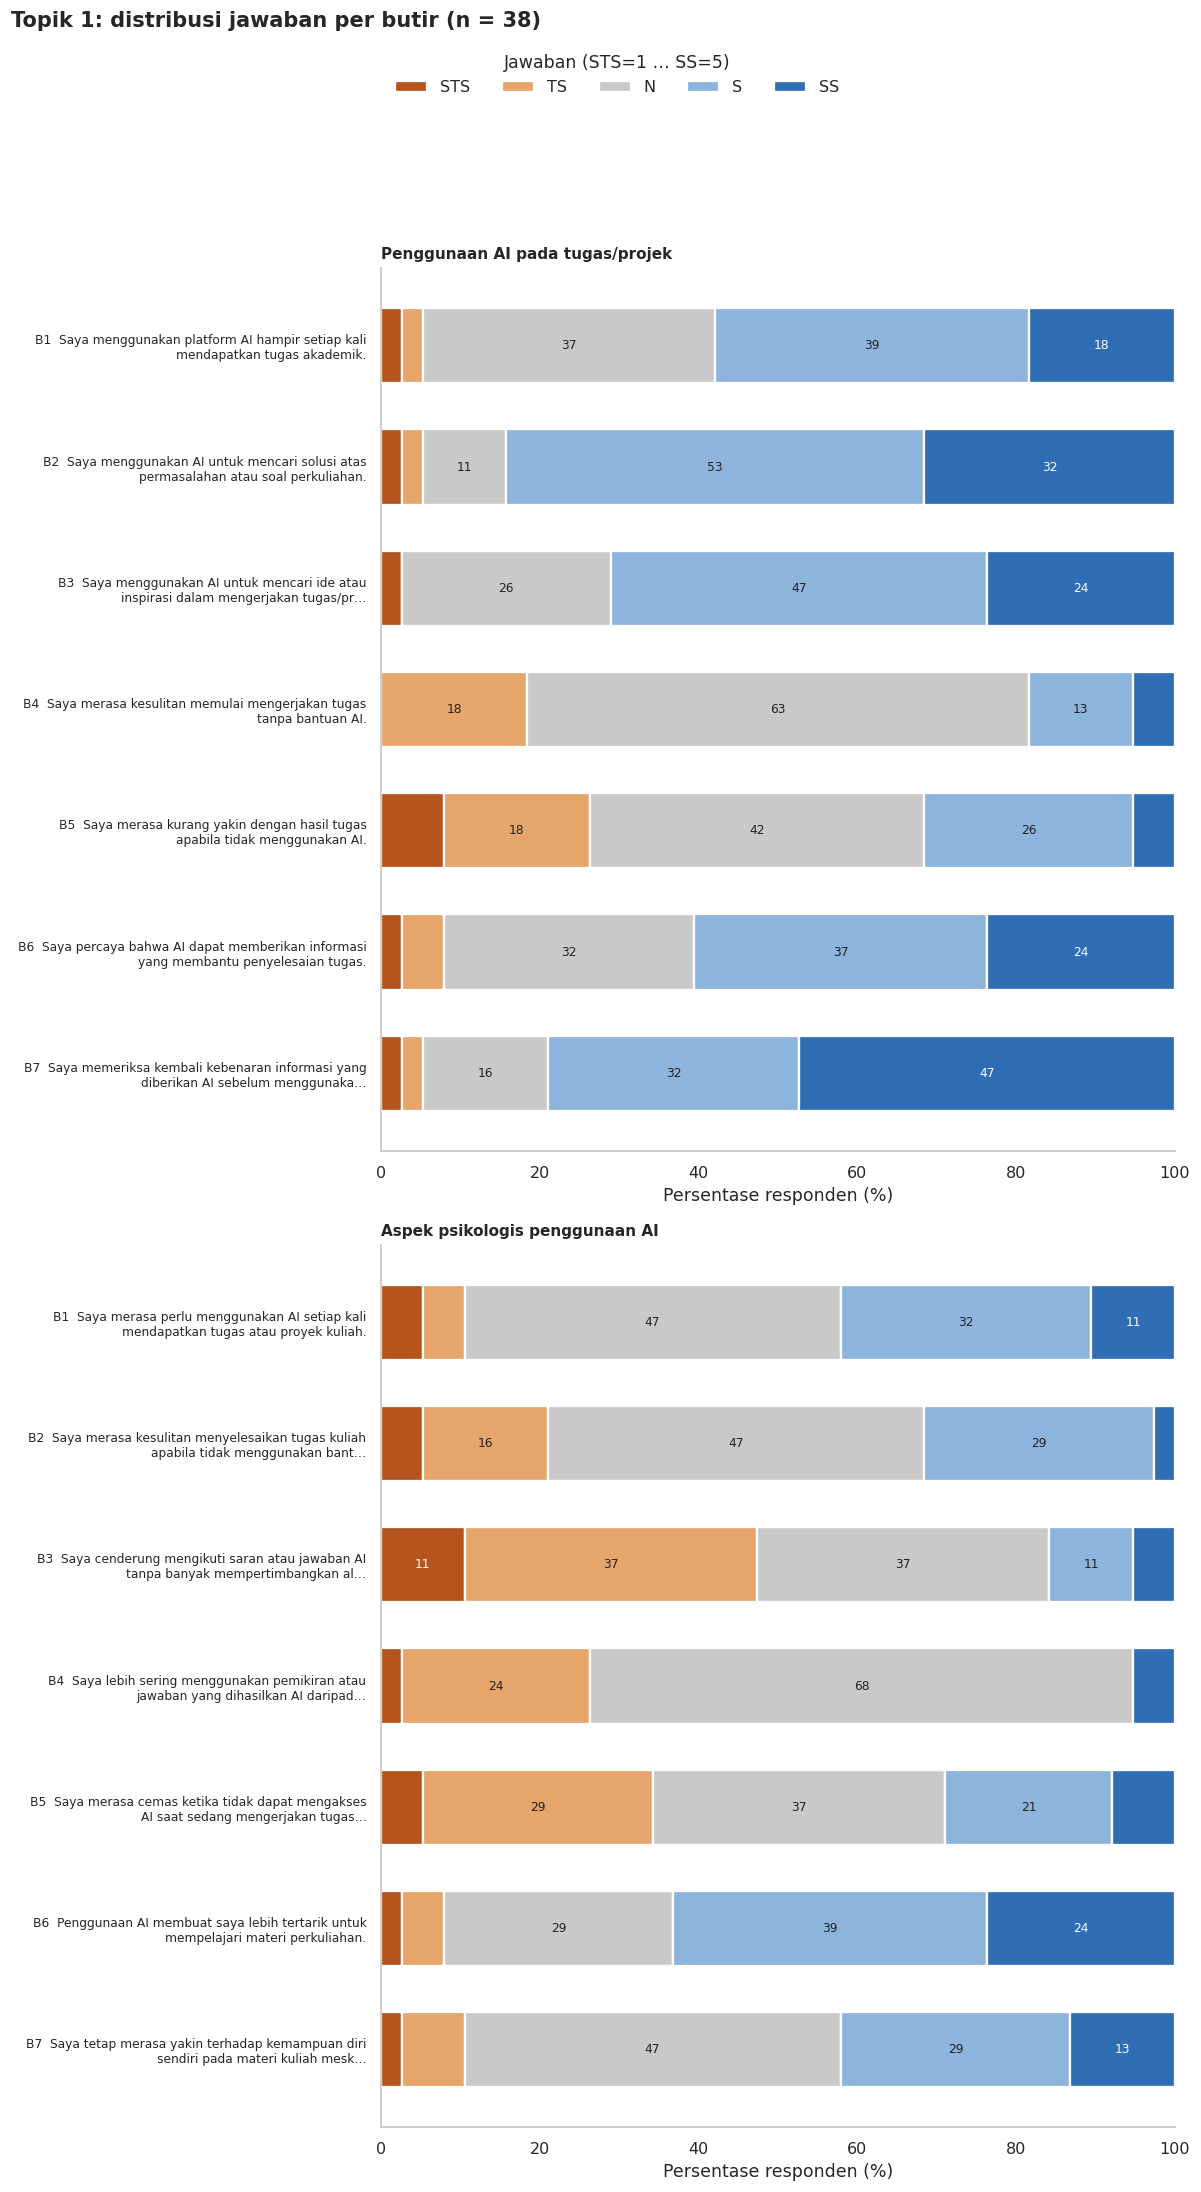

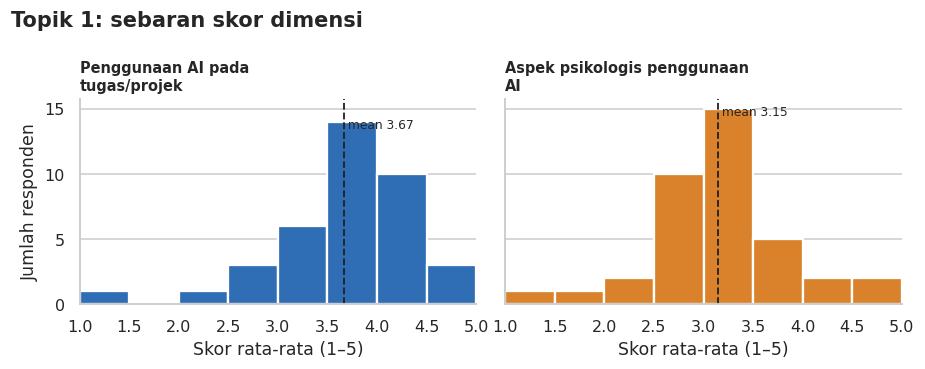

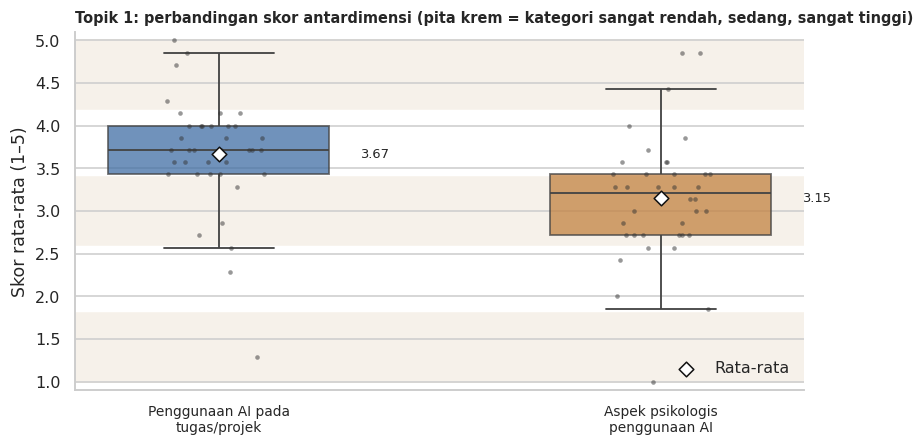

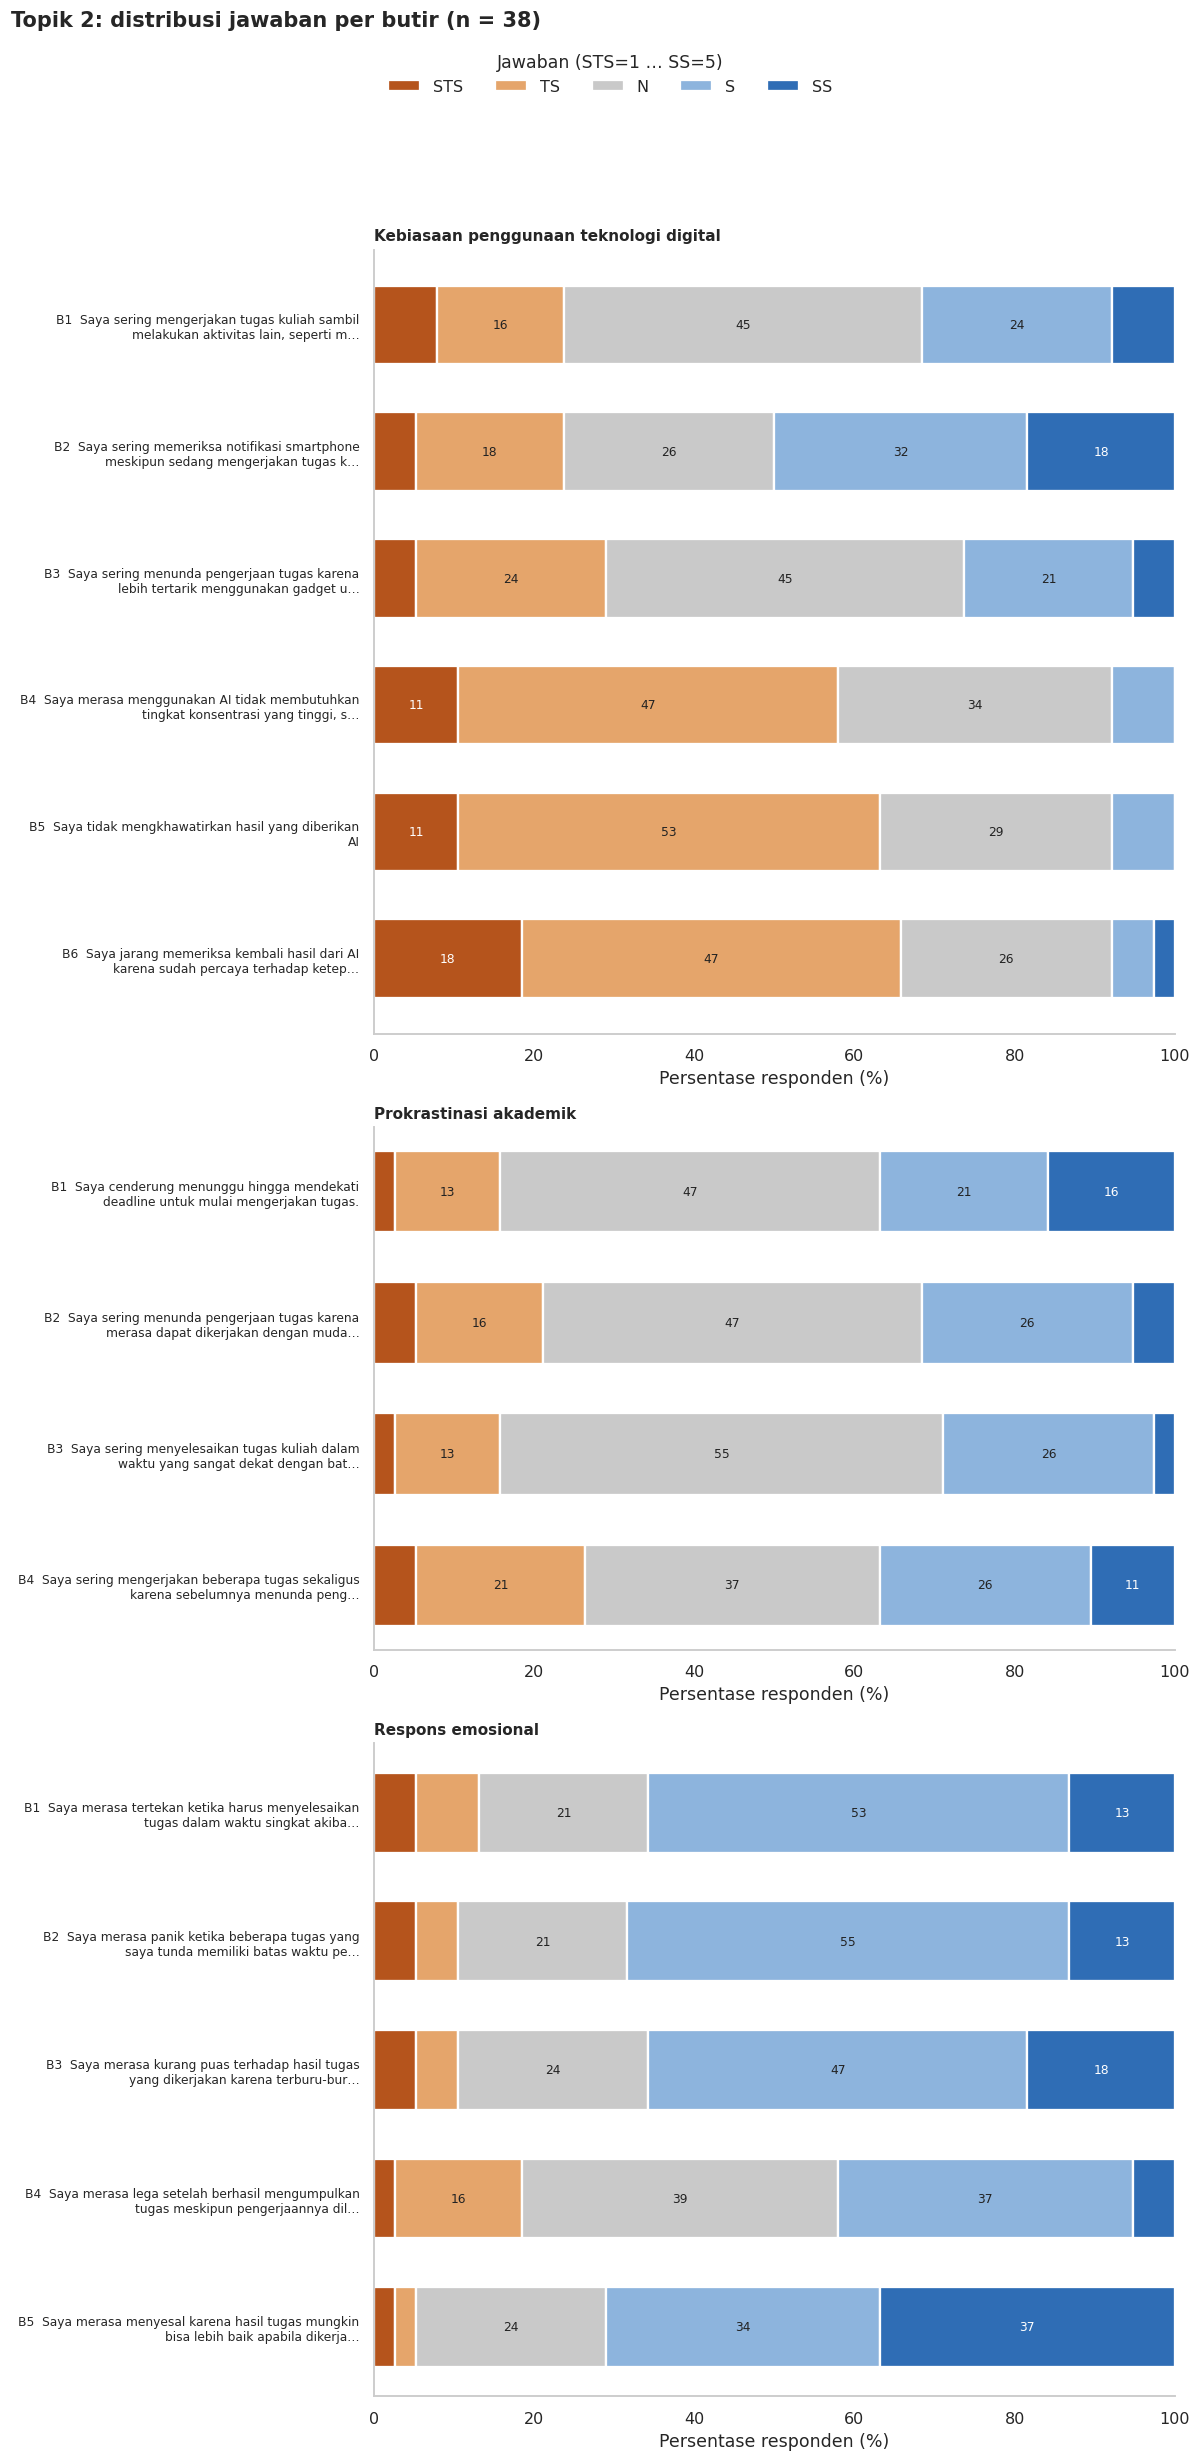

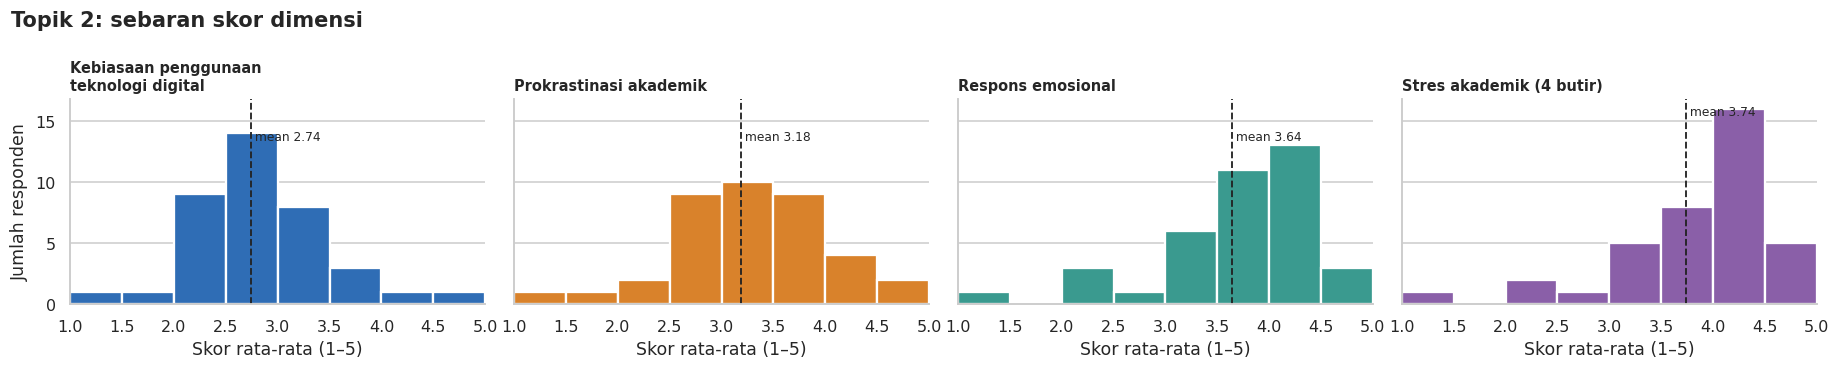

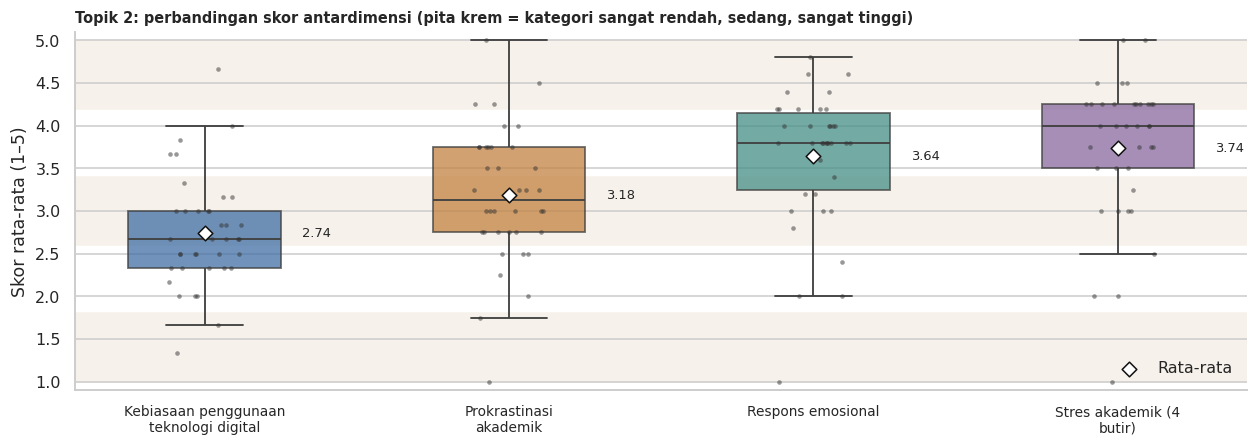

In [17]:
WARNA_LIKERT = {1: "#B5541C", 2: "#E5A56B", 3: "#C9C9C9", 4: "#8DB4DD", 5: "#2F6DB5"}   # oranye ↔ biru, netral abu
WARNA_DIM = ["#2F6DB5", "#D9822B", "#3A9A8F", "#8A5FA8"]
LABEL = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}

def potong(txt, n_=62):
    return textwrap.fill(txt if len(txt) <= n_ + 20 else txt[:n_ + 17] + "…", 48)

def grafik_distribusi(topik, nama_file_):
    dims = [(kd, d) for kd, d in DIM.items() if d["topik"] == topik]
    tinggi = [len(d["butir"]) for _, d in dims]
    fig, axes = plt.subplots(len(dims), 1, figsize=(11, 1.25 * sum(tinggi) + 1.2 * len(dims)),
                             gridspec_kw={"height_ratios": tinggi}, squeeze=False)
    for ax, (kd, d) in zip(axes[:, 0], dims):
        ys = np.arange(len(d["butir"]))[::-1]; kiri = np.zeros(len(d["butir"]))
        for sk_ in [1, 2, 3, 4, 5]:
            pct = np.array([(num[b] == sk_).mean() * 100 for b in d["butir"]])
            ax.barh(ys, pct, left=kiri, color=WARNA_LIKERT[sk_], edgecolor="white", linewidth=1.5,
                    height=0.62, label=LABEL[sk_])
            for y_, l_, p_ in zip(ys, kiri, pct):
                if p_ >= 8: ax.text(l_ + p_ / 2, y_, f"{p_:.0f}", ha="center", va="center", fontsize=8,
                                    color="white" if sk_ in (1, 5) else "#222")
            kiri += pct
        ax.set_yticks(ys)
        ax.set_yticklabels([f"{b.split('_')[1]}  " + potong(kamus.set_index('Kode').loc[b, 'Pernyataan']) for b in d["butir"]], fontsize=8)
        ax.set_xlim(0, 100); ax.set_xlabel("Persentase responden (%)"); ax.set_title(d["nama"], loc="left", fontsize=10)
        ax.grid(False)
    axes[0, 0].legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.18), frameon=False, title="Jawaban (STS=1 … SS=5)")
    fig.suptitle(f"{topik}: distribusi jawaban per butir (n = {n})", x=0.01, ha="left", fontweight="bold", y=1.0)
    fig.tight_layout(); fig.savefig(f"{OUT}/grafik/{nama_file_}", bbox_inches="tight"); plt.show()

def grafik_histogram(topik, nama_file_):
    daftar = skor_topik[topik]
    fig, axes = plt.subplots(1, len(daftar), figsize=(4.2 * len(daftar), 3.4), sharey=True, squeeze=False)
    for ax, nm, w in zip(axes[0], daftar, WARNA_DIM):
        ax.hist(skor[nm], bins=np.arange(1, 5.01, 0.5), color=w, edgecolor="white", linewidth=1.5)
        ax.axvline(skor[nm].mean(), color="#222", ls="--", lw=1.2)
        ax.text(skor[nm].mean(), ax.get_ylim()[1] * 0.97, f" mean {skor[nm].mean():.2f}", fontsize=8, va="top")
        ax.set_title(textwrap.fill(nm, 28), fontsize=9.5, loc="left"); ax.set_xlim(1, 5); ax.set_xlabel("Skor rata-rata (1–5)")
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("Jumlah responden")
    fig.suptitle(f"{topik}: sebaran skor dimensi", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); fig.savefig(f"{OUT}/grafik/{nama_file_}", bbox_inches="tight"); plt.show()

def grafik_boxplot(topik, nama_file_):
    daftar = skor_topik[topik]
    fig, ax = plt.subplots(figsize=(1.9 * len(daftar) + 4, 4.2))
    long = skor[daftar].melt(var_name="Dimensi", value_name="Skor")
    for lo, hi, c in [(1, 1.8, "#F6F1EA"), (2.6, 3.4, "#F6F1EA"), (4.2, 5, "#F6F1EA")]:
        ax.axhspan(lo, hi, color=c, zorder=0)
    sns.boxplot(data=long, x="Dimensi", y="Skor", order=daftar, palette=WARNA_DIM[:len(daftar)], width=0.5,
                fliersize=0, linewidth=1.2, ax=ax, boxprops=dict(alpha=0.75))
    sns.stripplot(data=long, x="Dimensi", y="Skor", order=daftar, color="#333", size=3, alpha=0.5, jitter=0.12, ax=ax)
    ax.scatter(range(len(daftar)), [skor[d].mean() for d in daftar], marker="D", s=46, color="white", edgecolor="#111", zorder=5, label="Rata-rata")
    for i, d in enumerate(daftar): ax.text(i + 0.32, skor[d].mean(), f"{skor[d].mean():.2f}", va="center", fontsize=8.5)
    ax.set_ylim(0.9, 5.1); ax.set_xlabel(""); ax.set_ylabel("Skor rata-rata (1–5)")
    ax.set_xticklabels([textwrap.fill(d, 20) for d in daftar], fontsize=9)
    ax.legend(loc="lower right", frameon=False); ax.grid(axis="x", visible=False)
    ax.set_title(f"{topik}: perbandingan skor antardimensi (pita krem = kategori sangat rendah, sedang, sangat tinggi)", loc="left", fontsize=9.5)
    fig.tight_layout(); fig.savefig(f"{OUT}/grafik/{nama_file_}", bbox_inches="tight"); plt.show()

for tp, kode_ in [("Topik 1", "topik1"), ("Topik 2", "topik2")]:
    grafik_distribusi(tp, f"{kode_}_1_distribusi_jawaban.png")
    grafik_histogram(tp, f"{kode_}_2_histogram_skor.png")
    grafik_boxplot(tp, f"{kode_}_3_boxplot_skor.png")

## Langkah 15. Menyimpan dan mengunduh hasil ke Excel

In [18]:
def fmt(df): return df.copy()

data_numerik = pd.concat([pend[["Jenis_Kelamin", "N_Platform_AI", "N_Platform_Premium", "Durasi_Gadget_ordinal"]], num, skor], axis=1)
data_numerik.insert(0, "Responden", range(1, n + 1))

readme = pd.DataFrame({"Keterangan": [
    f"Jumlah responden n = {n}; r tabel (α = 0,05 dua sisi, df = {n-2}) = {r_tabel:.3f}.",
    "Validitas: butir valid bila r hitung > r tabel (Pearson butir vs total dimensi). Corrected r = korelasi butir dengan total tanpa butir tersebut.",
    "Reliabilitas: Cronbach's α; kategori ≥0,90 sangat baik; 0,80–0,89 baik; 0,70–0,79 reliabel; <0,70 tidak reliabel.",
    "Seluruh uji dilakukan per dimensi; butir antardimensi tidak digabung.",
    "Tidak ada butir yang dibalik skornya (lihat lembar Cek_Reverse). Lembar Sensitivitas hanya pembanding, bukan hasil utama.",
    "Skor dimensi = rata-rata skor butir (1–5). Interval kategori: lebar (5−1)/5 = 0,80.",
    "Lembar Korelasi_Antardimensi dan Normalitas adalah diagnostik, bukan pengujian hipotesis.",
]})

lembar = {
    "README": readme, "Kamus_Butir": kamus,
    "Pembersihan": tabel_pembersihan, "Perubahan_Judul_Kolom": perubahan, "Konversi_Var_Pendukung": log_pend,
    "T1_Validitas": tabel_validitas[tabel_validitas.Topik == "Topik 1"].drop(columns="Topik"),
    "T1_Reliabilitas": tabel_reliabilitas[tabel_reliabilitas.Topik == "Topik 1"].drop(columns="Topik"),
    "T1_Deskriptif_Dimensi": tabel_desk_dim[tabel_desk_dim.Topik == "Topik 1"].drop(columns="Topik"),
    "T1_Frekuensi_Dimensi": tabel_frek_dim[tabel_frek_dim.Topik == "Topik 1"].drop(columns="Topik"),
    "T1_Deskriptif_Butir": tabel_desk_butir[tabel_desk_butir.Topik == "Topik 1"].drop(columns="Topik"),
    "T1_Var_Pendukung": tabel_pend,
    "T2_Validitas": tabel_validitas[tabel_validitas.Topik == "Topik 2"].drop(columns="Topik"),
    "T2_Reliabilitas": tabel_reliabilitas[tabel_reliabilitas.Topik == "Topik 2"].drop(columns="Topik"),
    "T2_Deskriptif_Dimensi": tabel_desk_dim[tabel_desk_dim.Topik == "Topik 2"].drop(columns="Topik"),
    "T2_Frekuensi_Dimensi": tabel_frek_dim[tabel_frek_dim.Topik == "Topik 2"].drop(columns="Topik"),
    "T2_Deskriptif_Butir": tabel_desk_butir[tabel_desk_butir.Topik == "Topik 2"].drop(columns="Topik"),
    "Cek_Reverse": cek_reverse, "T2_Sensitivitas_Reliab": tabel_sens_rel, "T2_Sensitivitas_Validitas": tabel_sens_val,
    "Normalitas": tabel_norm, "Korelasi_Antardimensi": tabel_kor, "Data_Numerik": data_numerik,
}

nama_xlsx = f"{OUT}/hasil_uji_validitas_reliabilitas.xlsx"
with pd.ExcelWriter(nama_xlsx, engine="openpyxl") as w:
    for nm, d_ in lembar.items():
        d_.round(4).to_excel(w, sheet_name=nm[:31], index=False)
        ws = w.sheets[nm[:31]]
        ws.freeze_panes = "A2"
        from openpyxl.styles import Font, PatternFill, Alignment
        for c in ws[1]:
            c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="2F6DB5")
            c.alignment = Alignment(wrap_text=True, vertical="center")
        for col in ws.columns:
            mx = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[col[0].column_letter].width = min(max(10, mx + 2), 70)
print("Tersimpan:", nama_xlsx)

# Ringkasan numerik (untuk dokumentasi/laporan)
with open(f"{OUT}/ringkasan_hasil.json", "w", encoding="utf-8") as f:
    json.dump({"n": n, "r_tabel": r_tabel, "r_min_80": r_min,
               "validitas": tabel_validitas.to_dict("records"), "reliabilitas": tabel_reliabilitas.to_dict("records")},
              f, ensure_ascii=False, default=float, indent=1)

if DI_COLAB:
    files.download(nama_xlsx)
    import shutil; shutil.make_archive("grafik_hasil", "zip", f"{OUT}/grafik"); files.download("grafik_hasil.zip")

Tersimpan: hasil/hasil_uji_validitas_reliabilitas.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Pedoman membaca hasil
* **Validitas:** butir valid bila r hitung > r tabel; corrected r ≥ 0,30 sebagai pembanding yang lebih ketat.
* **Reliabilitas:** gunakan kategori α pada modul; α jika dihapus yang lebih tinggi dari α dimensi menandai butir yang perlu **ditinjau isinya**, bukan otomatis dibuang.
* Tidak ada butir atau responden yang dihapus pada notebook ini; setiap perubahan instrumen harus punya alasan statistik **dan** isi.